# <span style="color:darkblue"> Lecture 17: Neural Networks and Tensor Flow </span>

<font size = "5">

In this class we will talk about how to set up <br>
a neural network classifier using Tensor Flow

For an introduction

https://www.youtube.com/watch?v=i8NETqtGHms

# <span style="color:darkblue"> I. Setup Working Environment </span>



<font size = "5">

We will be using a new library called "Tensor Flow" that is used <br>
to create neural network architectures

In Windows (Anaconda Prompt) or Mac (Terminal) type:

``` conda install tensorflow ```

In [6]:
# Import the package for the University of California Irvine API
from ucimlrepo import fetch_ucirepo 

# Import SK-Learn library for machine learning functions
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate
from sklearn import preprocessing
from sklearn.metrics import get_scorer_names


# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


<font size = "5">

Import tensor flow packages

In [7]:

# Import standard data analysis packages
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense

# <span style="color:darkblue"> II. Data </span>

<font size = "5">

Online Shoppers Purchasing Intention Dataset (OSHPID)

- This dataset contains information about user sessions
- It contains features data about user behavior 
while <br> navigating website
- The goal is to predict whether the customer will purchase or not

https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset


In [8]:
# Fetch online data from the UC Irvine Machine Learning Repository API
online_shopping= fetch_ucirepo(id=468) 

# Extract
X = online_shopping.data.features
# Drop columns that contain non-numeric values
X = X.drop(columns = ["Month","VisitorType"])

# Extract label data
y = online_shopping.data.targets["Revenue"]


In [9]:
# Convert to float types (avoids issues down the line)
X = np.asarray(X).astype(np.float32)
y = np.asarray(y).astype(np.float32)

<font size = "5">

Pre-process data prior to running model

In [10]:
# Split into training and test
X_train, X_test, y_train, y_test = train_test_split(X,y , 
                                   random_state=104,  
                                   test_size=0.25,  
                                   shuffle=True) 

In [11]:
# The first step is to produce a "scaler" function
scaler_train = preprocessing.StandardScaler().fit(X_train)
scaler_test  = preprocessing.StandardScaler().fit(X_test)

# Apply scaler function
X_train_scale = scaler_train.transform(X_train)
X_test_scale  = scaler_test.fit(X_test).transform(X_test)

# <span style="color:darkblue"> III. Training a neural network </span>


<font size = "5">

Define number of features in $X$

In [26]:
k_features = X.shape[1]
print(k_features)

15


<font size = "5">

To define a neural network we start with a configuration setup

- We start with an empty canvas with "Keras"
- Then we successively add how many layers we want <br>
and what type

For more information about Keras layers:

https://www.educative.io/answers/what-are-keras-layers

In [13]:
# "basic_model" for now only starts with a configuration

basic_model = keras.models.Sequential()

In [14]:
# We add how many layers we want, starting with the input layer and 
# ending with the output layer

# This has a dense layer for inputs with "k" features
basic_model.add(Dense(units=16, activation='relu', input_shape=(k_features,)))

# This is the output layer. The sigmoid defines predictions in (0,1)
# We choose 1 unit since there is a scalar output (binary classification)

basic_model.add(Dense(units = 1, activation='sigmoid'))

# Note: If you are using the neural network to predict continuous outcomes,
# you may want a different activation function in the output layer

/opt/anaconda3/envs/tf-env/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


<font size = "5">

Define an optimizer

In [15]:
# Adam is a type of optimization algorithm

adam = keras.optimizers.Adam(learning_rate=0.001)

In [16]:
# Define the loss function to optimize

basic_model.compile(loss='binary_crossentropy', optimizer=adam, metrics=["accuracy"])

<font size = "5">

Estimate model

- The optimization algorithm proceeds sequentially, through epocs
- Set a random seed to ensure reproducibility

In [17]:
# Set random seed
tf.keras.utils.set_random_seed(0)  

# Train model
basic_model.fit(X_train, y_train, epochs=100)

Epoch 1/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 1s 601us/step - accuracy: 0.6948 - loss: 4.2214
Epoch 2/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 554us/step - accuracy: 0.8677 - loss: 0.6381
Epoch 3/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 530us/step - accuracy: 0.8682 - loss: 0.5316
Epoch 4/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 541us/step - accuracy: 0.8711 - loss: 0.5294
Epoch 5/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 594us/step - accuracy: 0.8657 - loss: 0.5396
Epoch 6/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 564us/step - accuracy: 0.8689 - loss: 0.5341
Epoch 7/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 566us/step - accuracy: 0.8697 - loss: 0.5207
Epoch 8/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 537us/step - accuracy: 0.8723 - loss: 0.4872
Epoch 9/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 547us/step - accuracy: 0.8719 - loss: 0.4407
Epoch 10/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 527us/step - accuracy: 0.8753 - loss: 0.4240
Epoch 11/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 539us/step - accuracy: 0.8714 - loss: 0.4380
Epoch 12/100
289/28

# <span style="color:darkblue"> IV. Evaluate a neural network </span>


<font size = "5">

Obtain predicted probabilities and convert them to {0,1}

In [19]:
# Convert to array
predicted_prob = basic_model.predict(X_test)
predicted_prob = tf.squeeze(predicted_prob)

# Convert to {0,1} predictions using a 0.5 threshold
threshold = 0.5
predicted = np.array([1 if x >= threshold else 0 for x in predicted_prob])

97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 455us/step


<font size = "5">

Obtain confusion matrix

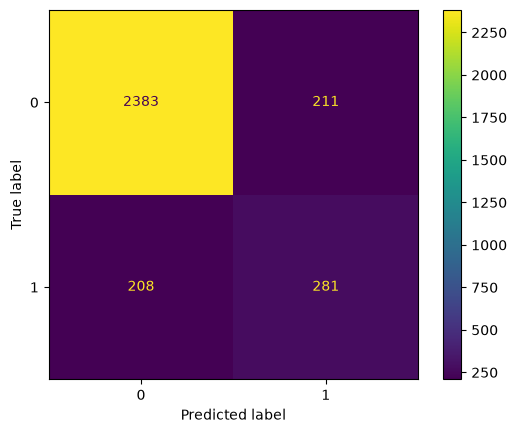

In [20]:
# Obtain confusion matrix
cm = confusion_matrix(y_test, predicted)

displ = ConfusionMatrixDisplay(confusion_matrix=cm)
displ.plot()

<font size = "5">

At the moment we defined a very simple neural network <br>
with just an input layer and an output layer. <br>

Try it yourself!

- Increase the number of units in the input layer
- Does prediction accuracy improve?


Epoch 1/100


/opt/anaconda3/envs/tf-env/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


289/289 ━━━━━━━━━━━━━━━━━━━━ 1s 627us/step - accuracy: 0.8352 - loss: 3.9397
Epoch 2/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 604us/step - accuracy: 0.8549 - loss: 0.9929
Epoch 3/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 588us/step - accuracy: 0.8568 - loss: 0.8225
Epoch 4/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 541us/step - accuracy: 0.8620 - loss: 0.7138
Epoch 5/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 537us/step - accuracy: 0.8549 - loss: 0.8577
Epoch 6/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 538us/step - accuracy: 0.8573 - loss: 0.8755
Epoch 7/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 534us/step - accuracy: 0.8560 - loss: 0.8606
Epoch 8/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 527us/step - accuracy: 0.8564 - loss: 0.8703
Epoch 9/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 535us/step - accuracy: 0.8562 - loss: 0.8623
Epoch 10/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 564us/step - accuracy: 0.8582 - loss: 0.8493
Epoch 11/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 538us/step - accuracy: 0.8591 - loss: 0.8350
Epoch 12/100
289/289 ━━━━━━━━━━

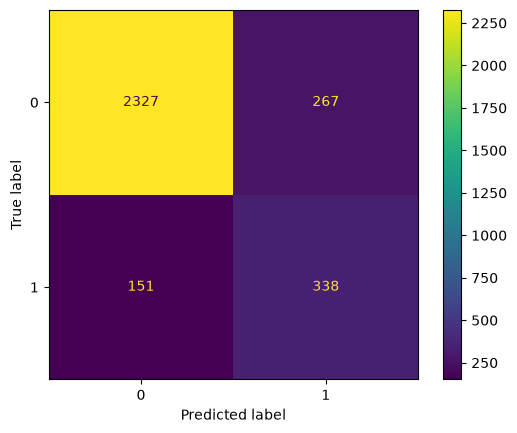

In [23]:
# Write your own code

# "basic_model" for now only starts with a configuration

basic_model = keras.models.Sequential()

# We add how many layers we want, starting with the input layer and 
# ending with the output layer

# This has a dense layer for inputs with "k" features
basic_model.add(Dense(units=32, activation='relu', input_shape=(k_features,)))

# This is the output layer. The sigmoid defines predictions in (0,1)
# We choose 1 unit since there is a scalar output (binary classification)

basic_model.add(Dense(units = 1, activation='sigmoid'))

# Note: If you are using the neural network to predict continuous outcomes,
# you may want a different activation function in the output layer

# Adam is a type of optimization algorithm

adam = keras.optimizers.Adam(learning_rate=0.001)

# Define the loss function to optimize

basic_model.compile(loss='binary_crossentropy', optimizer=adam, metrics=["accuracy"])

# Set random seed
tf.keras.utils.set_random_seed(0)  

# Train model
basic_model.fit(X_train, y_train, epochs=100)

# Convert to array
predicted_prob = basic_model.predict(X_test)
predicted_prob = tf.squeeze(predicted_prob)

# Convert to {0,1} predictions using a 0.5 threshold
threshold = 0.5
predicted = np.array([1 if x >= threshold else 0 for x in predicted_prob])

# Obtain confusion matrix
cm = confusion_matrix(y_test, predicted)

displ = ConfusionMatrixDisplay(confusion_matrix=cm)
displ.plot()

<font size = "5">


Try it yourself!

- Add one or more hidden layers
- Does prediction accuracy improve?

Epoch 1/100


/opt/anaconda3/envs/tf-env/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


289/289 ━━━━━━━━━━━━━━━━━━━━ 2s 773us/step - accuracy: 0.8018 - loss: 1.0753
Epoch 2/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 869us/step - accuracy: 0.8462 - loss: 0.4732
Epoch 3/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 681us/step - accuracy: 0.8648 - loss: 0.4118
Epoch 4/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 719us/step - accuracy: 0.8716 - loss: 0.3837
Epoch 5/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 760us/step - accuracy: 0.8728 - loss: 0.3579
Epoch 6/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 742us/step - accuracy: 0.8755 - loss: 0.3494
Epoch 7/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 719us/step - accuracy: 0.8836 - loss: 0.3138
Epoch 8/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 717us/step - accuracy: 0.8837 - loss: 0.3082
Epoch 9/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 681us/step - accuracy: 0.8765 - loss: 0.3352
Epoch 10/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 673us/step - accuracy: 0.8849 - loss: 0.3044
Epoch 11/100
289/289 ━━━━━━━━━━━━━━━━━━━━ 0s 676us/step - accuracy: 0.8830 - loss: 0.2991
Epoch 12/100
289/289 ━━━━━━━━━━

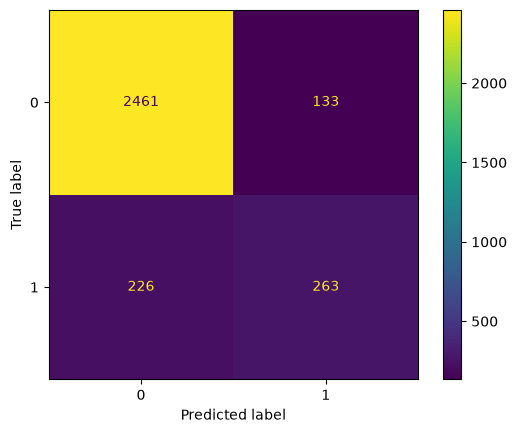

In [24]:
# Write your own code

# Write your own code

# "basic_model" for now only starts with a configuration

basic_model = keras.models.Sequential()

# We add how many layers we want, starting with the input layer and 
# ending with the output layer

# This has a dense layer for inputs with "k" features
basic_model.add(Dense(units=32, activation='relu', input_shape=(k_features,)))

# This has a dense layer for inputs with "k" features
basic_model.add(Dense(units=64, activation='relu', input_shape=(k_features,)))

# This has a dense layer for inputs with "k" features
basic_model.add(Dense(units=16, activation='relu', input_shape=(k_features,)))

# This has a dense layer for inputs with "k" features
basic_model.add(Dense(units=32, activation='relu', input_shape=(k_features,)))

# This has a dense layer for inputs with "k" features
basic_model.add(Dense(units=16, activation='relu', input_shape=(k_features,)))

# This is the output layer. The sigmoid defines predictions in (0,1)
# We choose 1 unit since there is a scalar output (binary classification)

basic_model.add(Dense(units = 1, activation='sigmoid'))

# Note: If you are using the neural network to predict continuous outcomes,
# you may want a different activation function in the output layer

# Adam is a type of optimization algorithm

adam = keras.optimizers.Adam(learning_rate=0.001)

# Define the loss function to optimize

basic_model.compile(loss='binary_crossentropy', optimizer=adam, metrics=["accuracy"])

# Set random seed
tf.keras.utils.set_random_seed(0)  

# Train model
basic_model.fit(X_train, y_train, epochs=100)

# Convert to array
predicted_prob = basic_model.predict(X_test)
predicted_prob = tf.squeeze(predicted_prob)

# Convert to {0,1} predictions using a 0.5 threshold
threshold = 0.5
predicted = np.array([1 if x >= threshold else 0 for x in predicted_prob])

# Obtain confusion matrix
cm = confusion_matrix(y_test, predicted)

displ = ConfusionMatrixDisplay(confusion_matrix=cm)
displ.plot()




<font size = "5">

Try it yourself!

- Import the Mashable dataset that we used earlier <br>
(you can find this in this in the ```ArticlesTrain.csv``` and <br>
```ArticlesTest.csv``` files in the ```data_raw``` folder)

- Try to set up a neural network with a simple input-output layer 

In [ ]:
# Write your own code

articles_train  = pd.read_csv("data_raw/ArticlesTrain.csv")
articles_test   = pd.read_csv("data_raw/ArticlesTest.csv")

# Extract all columns except "shares" (the outcome)
X_train = articles_train.drop(columns = ["shares"])
X_test  = articles_test.drop(columns = ["shares"])

# Extract shares (the outcome)
y_train = articles_train[["shares"]]
y_test = articles_test[["shares"]]

# The first step is to produce a "scaler" function
scaler_train = preprocessing.StandardScaler().fit(X_train)
scaler_test  = preprocessing.StandardScaler().fit(X_test)

# Apply scaler function
X_train_scale = scaler_train.transform(X_train)
X_test_scale  = scaler_test.fit(X_test).transform(X_test)

k_features = X_train.shape[1]
print(k_features)

# "basic_model" for now only starts with a configuration

basic_model = keras.models.Sequential()

# We add how many layers we want, starting with the input layer and 
# ending with the output layer

# This has a dense layer for inputs with "k" features
basic_model.add(Dense(units=32, activation='relu', input_shape=(k_features,)))

# This is the output layer. The sigmoid defines predictions in (0,1)
# We choose 1 unit since there is a scalar output (binary classification)

basic_model.add(Dense(units = 1, activation='sigmoid'))

# Note: If you are using the neural network to predict continuous outcomes,
# you may want a different activation function in the output layer

# Adam is a type of optimization algorithm

adam = keras.optimizers.Adam(learning_rate=0.001)

# Define the loss function to optimize

basic_model.compile(loss='binary_crossentropy', optimizer=adam, metrics=["accuracy"])

# Set random seed
tf.keras.utils.set_random_seed(0)  

# Train model
basic_model.fit(X_train, y_train, epochs=100)

# Convert to array
#predicted_prob = basic_model.predict(X_test)
#predicted_prob = tf.squeeze(predicted_prob)

# Convert to {0,1} predictions using a 0.5 threshold
threshold = 0.5
predicted = np.array([1 if x >= threshold else 0 for x in predicted_prob])

# Obtain confusion matrix
#cm = confusion_matrix(y_test, predicted)

#displ = ConfusionMatrixDisplay(confusion_matrix=cm)
#displ.plot()


15
Epoch 1/100


/opt/anaconda3/envs/tf-env/lib/python3.11/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 with name 'None' of layer 'dense_24' is incompatible with the layer: expected axis -1 of input shape to have value 15, but received input with shape (None, 50)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(None, 50), dtype=float32)
  • training=True
  • mask=None
  • kwargs=<class 'inspect._empty'>

# <span style="color:darkblue"> V. Additional resources </span>

<font size = "5">

Quick guide:

https://www.tensorflow.org/tutorials/quickstart/beginner

Binary classification:

https://www.freecodecamp.org/news/binary-classification-made-simple-with-tensorflow/

Image classification:

https://www.tensorflow.org/tutorials/images/classification

